## The Dirichlet distribution

## What if the prize wasn't binary in the multi-armed bandit problem?

## What if for each arm we have many multiple outcomes, and we wish to maximize the (expected value)?

The analysis we ran before will not be feasible since the likelihood was binomial. For this purpose we use the Dirichlet distribution.

## $p\sim Beta(\alpha, \beta)$
## Lets change the notation:

## $p\sim Beta(\alpha_1, \alpha_2)$

## If we get the probability to success $p$ then the probability of failure is $1-p$
## In other words:

## $(p, 1-p)\sim Beta(\alpha_1, \alpha_2)$

## Intead of $(p,1-p)$, lets call it $(\theta_1, \theta_2)$.


## let $\alpha = (\alpha_1, \alpha_2)$

and,

##  $\alpha_0 = \alpha_1  + \alpha_2$

## Beta pdf

## $$ f_X(x;\theta_1, \theta_2) =  \frac{\theta_1^{\alpha_1-1}\theta_2^{\alpha_2-1}}{B(\alpha_0)}$$

where, 

## $$ B(\alpha) = \frac{\Gamma(\alpha_1)\Gamma(\alpha_2)}{\Gamma(\alpha_0)} $$ 


Properties:

## $$ \theta = (\theta_1,..., \theta_n), $$
##     $$ \alpha = (\alpha_1,..., \alpha_n), \alpha_i >0 $$

Let $\theta$ follow a Dirichlet distribution:

## $$ \theta \sim Dir(\alpha) $$

With the following PDF:

## $$ p(\theta) = \frac{1}{B(\alpha)}\prod_{i=1}^n\theta_i^{\alpha_i-1}I(\theta \in S), $$

where

## $$ S = \left\{\theta \in R^n, \theta \geq 0, \sum_{i=1}^n \theta_i =1 \right\} $$

In case you are wondering what $B(\alpha)$ is:

$$ \frac{\Gamma(\alpha_1)\Gamma(\alpha_2)...\Gamma(\alpha_n),}{\Gamma(\alpha_0)} $$

where $\alpha_0 = \sum_{i=1}^n \alpha_i$

More properties:

$$E[\theta_i] = \frac{\alpha_i}{\alpha_0} $$ 

$$ mode(\theta) = \left(\frac{\alpha_1-1}{\alpha_0},...,\frac{\alpha_n-1}{\alpha_0}   \right) $$

$$ Var(\theta_i) = \frac{\alpha_i(\alpha_0-\alpha_i)}{\alpha_0^2(\alpha_0+1)} $$

In case we have a 2-dimentional Dirichlet distribution:

$$ p(\theta) = \frac{1}{B(\alpha)}\prod_{i=1}^2\theta_i^{\alpha_i-1}I(\theta \in S) = \frac{1}{B(\alpha)}\theta_1^{\alpha_1-1}\theta_2^{\alpha_2-1} I(\theta \in S) =\frac{1}{B(\alpha)}\theta_1^{\alpha_1-1}(1-\theta_1)^{\alpha_2-1} I(\theta \in S)= \frac{1}{B(\alpha)}\theta_1^{\alpha_1-1}(1-\theta_1)^{\alpha_2-1} , $$

We get the Beta Distribution!!


C:\Users\Eshel\AppData\Local\Temp\ipykernel_42580\1798976592.py:18: DeprecationWarning: Arrays of 2-dimensional vectors are deprecated. Use arrays of 3-dimensional vectors instead. (deprecated in NumPy 2.0)
  tri_area = lambda xy, pair: 0.5 * np.linalg.norm(np.cross(*(pair - xy)))
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


Wrote plots to "dirichlet_plots.png".


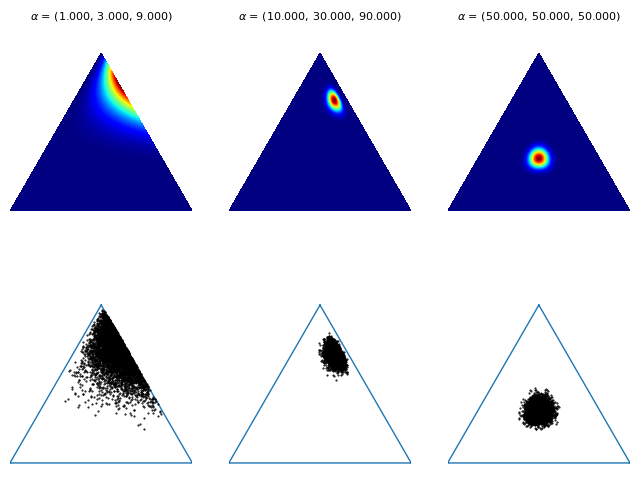

In [1]:
'''Functions for drawing contours of Dirichlet distributions.'''

# Author: Thomas Boggs

from __future__ import division, print_function

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.tri as tri

_corners = np.array([[0, 0], [1, 0], [0.5, 0.75**0.5]])
_AREA = 0.5 * 1 * 0.75**0.5
_triangle = tri.Triangulation(_corners[:, 0], _corners[:, 1])

# For each corner of the triangle, the pair of other corners
_pairs = [_corners[np.roll(range(3), -i)[1:]] for i in range(3)]
# The area of the triangle formed by point xy and another pair or points
tri_area = lambda xy, pair: 0.5 * np.linalg.norm(np.cross(*(pair - xy)))

def xy2bc(xy, tol=1.e-4):
    '''Converts 2D Cartesian coordinates to barycentric.
    Arguments:
        `xy`: A length-2 sequence containing the x and y value.
    '''
    coords = np.array([tri_area(xy, p) for p in _pairs]) / _AREA
    return np.clip(coords, tol, 1.0 - tol)

class Dirichlet(object):
    def __init__(self, alpha):
        '''Creates Dirichlet distribution with parameter `alpha`.'''
        from math import gamma
        from operator import mul
        self._alpha = np.array(alpha)
        self._coef = gamma(np.sum(self._alpha)) / \
                     np.multiply.reduce([gamma(a) for a in self._alpha])
    def pdf(self, x):
        '''Returns pdf value for `x`.'''
        from operator import mul
        return self._coef * np.multiply.reduce([xx ** (aa - 1)
                                                for (xx, aa)in zip(x, self._alpha)])
    def sample(self, N):
        '''Generates a random sample of size `N`.'''
        return np.random.dirichlet(self._alpha, N)

def draw_pdf_contours(dist, border=False, nlevels=200, subdiv=8, **kwargs):
    '''Draws pdf contours over an equilateral triangle (2-simplex).
    Arguments:
        `dist`: A distribution instance with a `pdf` method.
        `border` (bool): If True, the simplex border is drawn.
        `nlevels` (int): Number of contours to draw.
        `subdiv` (int): Number of recursive mesh subdivisions to create.
        kwargs: Keyword args passed on to `plt.triplot`.
    '''
    from matplotlib import ticker, cm
    import math

    refiner = tri.UniformTriRefiner(_triangle)
    trimesh = refiner.refine_triangulation(subdiv=subdiv)
    pvals = [dist.pdf(xy2bc(xy)) for xy in zip(trimesh.x, trimesh.y)]

    plt.tricontourf(trimesh, pvals, nlevels, cmap='jet', **kwargs)
    plt.axis('equal')
    plt.xlim(0, 1)
    plt.ylim(0, 0.75**0.5)
    plt.axis('off')
    if border is True:
        plt.triplot(_triangle, linewidth=1)

def plot_points(X, barycentric=True, border=True, **kwargs):
    '''Plots a set of points in the simplex.
    Arguments:
        `X` (ndarray): A 2xN array (if in Cartesian coords) or 3xN array
                       (if in barycentric coords) of points to plot.
        `barycentric` (bool): Indicates if `X` is in barycentric coords.
        `border` (bool): If True, the simplex border is drawn.
        kwargs: Keyword args passed on to `plt.plot`.
    '''
    if barycentric is True:
        X = X.dot(_corners)
    plt.plot(X[:, 0], X[:, 1], 'k.', ms=1, **kwargs)
    plt.axis('equal')
    plt.xlim(0, 1)
    plt.ylim(0, 0.75**0.5)
    plt.axis('off')
    if border is True:
        plt.triplot(_triangle, linewidth=1)

const1 = 1
const2 = 10
        
f = plt.figure(figsize=(8, 6))
alphas = [const1*np.array([1,3,9]) ,
          const2*np.array([1,3,9]),
          [50, 50,50]]
for (i, alpha) in enumerate(alphas):
    plt.subplot(2, len(alphas), i + 1)
    dist = Dirichlet(alpha)
    draw_pdf_contours(dist)
    title = r'$\alpha$ = (%.3f, %.3f, %.3f)' % tuple(alpha)
    plt.title(title, fontdict={'fontsize': 8})
    plt.subplot(2, len(alphas), i + 1 + len(alphas))
    plot_points(dist.sample(5000))
plt.savefig('dirichlet_plots.png')
print('Wrote plots to "dirichlet_plots.png".')

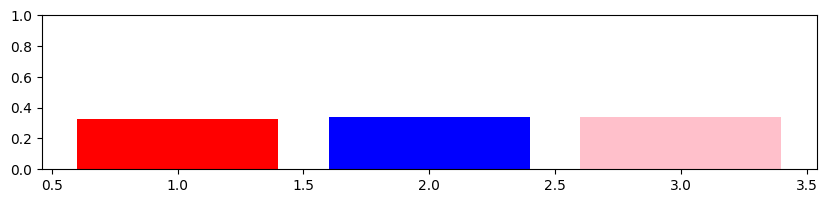

In [2]:
## Sample Dirichlet
plt.figure(figsize=(10,2))
plt.bar(np.array([1,2,3]), np.random.dirichlet(np.array([10000,10000,10000])), color = ('red', 'blue', 'pink'))
plt.ylim(0,1)
plt.show()

In [3]:
const = 1
np.random.dirichlet(const*np.array([1,3,9]))

array([0.0202491 , 0.19631425, 0.78343665])

## Dirichlet Categorial model

Let $X_1, X_2,...,X_n \sim Cat(\theta)$

where $\theta = (\theta_1, ..., \theta_m)$, $\theta_i >0, \forall i \in \{1,...,m\}$, such that:

$$ P(X_i = j|\theta)= \theta_j $$

Finally, $X_1,...,X_n$ are independant given $\theta$.

We assume that $\theta \sim Dir(\alpha)$, thus:

$$ p(\theta|\alpha) \propto \prod_{i=1}\theta_i^{\alpha_i-1}I(\theta \in S), $$

Let $D=(x_1,x_2,...,x_n)$ be our data
The likelihood function is:

$$ P(D|\theta) = \prod_{i=1}^n P(X_i=x_i|\theta)= \prod_{i=1}^n \theta_{x_i} = \prod_{i=1}^n \prod_{j=1}^m \theta_{j}^{I(x_i=j)} = \prod_{j=1}^m \theta_{j}^{\sum I(x_i=j)}= \prod_{j=1}^m \theta_{j}^{c_j}  $$,

where $c_j$ is the number of times we got category $j$.

## And now, the beuatiful part...

This was our likelihood:
$$ P(D|\theta)= \prod_{j=1}^m \theta_{j}^{c_j}  $$ 

The prior is: 

$$ P(\theta) \propto  \prod_{j=1}^{m}\theta_{j}^{\alpha_j-1}I(\theta \in S) $$

The posetrior is:

$$ P(\theta|D) \propto P(D|\theta)P(\theta) = \prod_{j=1}^m \theta_j^{c_j+\alpha_j-1}I(\theta \in S) \propto Dir(\theta| c+\alpha)  .$$



Thus the Dirichlet is a conjugate prior to categorial.

## Prediction
Given the data $D$ what is the probabiliy that the next sample will be category $j$?

$$ P(X_{new}=j|D) = \int P(X_{new}=j| D,\theta)P(\theta|D)d\theta = \int P(X_{new}=j| \theta)P(\theta|D)d\theta  = \int \theta_j P(\theta|D)d\theta$$

The last term is expectation of $\theta_j$, thus:

$$ P(X_{new}=j|D) = \frac{c_j+\alpha_j}{n+\alpha_0}  $$

## Multi-armed bandit problem with multiple prizes

Now, suppose that there is more than one possible value of winning a prize. Suppose, when playing a slot machine, one can win either 5 or 20 coins. How can we play the game and win the most number of coins?


Lets try to follow a few online algorithms:

Online Algorithm: an equivalent algorithm would be the following. 
1. For each machine we start with a Dirichlet prior, where $\alpha_i = 1$, for $i = \{1,2,3,...,n\}$. 
2. We sample a from Dirichlet distribution for each machine. Thus, we get a Categorial distribution.
3. For each machine we sample from the new Categorial distribution.    
4. We choose the machine with highest value. If there is more than one machine with max value we choose a machine arbitrary. We then sample again from the categorial distirubiton.
5. We update this machine Posterior.

In [4]:
possible_vals = [0, 5, 10]
num_machines = 5
num_out_comes = len(possible_vals)

num_trials = 350
true_probs = np.random.dirichlet(np.ones(num_out_comes), num_machines)
true_probs

array([[0.06445452, 0.02240389, 0.91314159],
       [0.14090955, 0.65920569, 0.19988476],
       [0.75541353, 0.11716992, 0.12741655],
       [0.10016021, 0.01441884, 0.88542096],
       [0.29844379, 0.56140182, 0.14015438]])

## Online algorithm

In [5]:
true_probs

array([[0.06445452, 0.02240389, 0.91314159],
       [0.14090955, 0.65920569, 0.19988476],
       [0.75541353, 0.11716992, 0.12741655],
       [0.10016021, 0.01441884, 0.88542096],
       [0.29844379, 0.56140182, 0.14015438]])

In [225]:
num_trials

350

In [6]:
def online():

    possible_vals = [0, 5, 10]
    num_machines = 5
    num_out_comes = len(possible_vals)
    slot_results = np.zeros((num_machines, num_out_comes))

    Dirichlet_parameters = np.ones((num_machines, num_out_comes))
    for ind in range(num_trials):
        
        # np.random.choice(aa_milne_arr, 1, p=curr_probs[0,:])
        machine_outcome = []
        curr_probs = np.zeros((num_machines, num_out_comes))
        for machine in range(num_machines):
            curr_probs[machine, :] = np.random.dirichlet(Dirichlet_parameters[machine,:])
            machine_outcome.append(np.random.choice(possible_vals, 1, p=curr_probs[machine,:])[0])
    
    
        machine_outcome_arr = np.array(machine_outcome)
        max_val = machine_outcome_arr.max()
        pp = np.where(machine_outcome_arr==max_val, 1,0)/np.where(machine_outcome_arr==max_val, 1,0).sum()
        optimal_machine = np.random.choice(num_machines, 1, p=pp)[0]
        outcome = np.random.choice(np.arange(num_out_comes), 1, p = np.random.dirichlet(true_probs[optimal_machine,:]))[0]
        Dirichlet_parameters[optimal_machine,outcome] += 1
        slot_results[optimal_machine,outcome] += 1
    
    return (slot_results*np.array(possible_vals)).sum()

online()

np.float64(2875.0)

## Upper Confidence bound

The ubc is operating as follows: we give each arm a score:


$$ \hat{\mu_r} + \sqrt{\frac{2Ln(t)}{N_t(r)}} , $$

where $t$ is the number of total trials so far,  $N_t(r)$ is the number of trial of the bandit $r$.

In [7]:
def UCB():

    possible_vals = [0, 5, 10] 
    num_machines = 5
    num_out_comes = len(possible_vals)
    slot_results = np.zeros((num_machines, num_out_comes))
    Dirichlet_parameters = np.ones((num_machines, num_out_comes))

    for ind in range(num_trials):
    
        mus = (Dirichlet_parameters[:,:]/Dirichlet_parameters[:,:].sum()*np.array(possible_vals)).sum(axis=1)
        # Num of trials for each machine N_i(t)
        Nt = Dirichlet_parameters.sum(axis = 1)-num_out_comes
        t = ind + 1
        UBC_results = mus + (2*np.log(t)/Nt)**0.5
        optimal_machine = np.argmax(UBC_results)
        outcome = np.random.choice(np.arange(num_out_comes), 1, p = np.random.dirichlet(true_probs[optimal_machine,:]))[0]
        Dirichlet_parameters[optimal_machine,outcome] += 1
        slot_results[optimal_machine,outcome] += 1
    
    return (slot_results*np.array(possible_vals)).sum()

UCB()

C:\Users\Eshel\AppData\Local\Temp\ipykernel_42580\1876684205.py:15: RuntimeWarning: invalid value encountered in divide
  UBC_results = mus + (2*np.log(t)/Nt)**0.5
C:\Users\Eshel\AppData\Local\Temp\ipykernel_42580\1876684205.py:15: RuntimeWarning: divide by zero encountered in divide
  UBC_results = mus + (2*np.log(t)/Nt)**0.5


np.float64(3135.0)

## Compering the two options

### We can run the experiment not once but many times and see on average the results

### Let see what happens if we run average of ten runs:

In [8]:
ucb_res = []
online_res = []

for ind in range(10):
    ucb_res.append(UCB())
    online_res.append(online())

print('online results is: ', np.array(online_res).mean())
print('UCB results is: ', np.array(ucb_res).mean())

C:\Users\Eshel\AppData\Local\Temp\ipykernel_42580\1876684205.py:15: RuntimeWarning: invalid value encountered in divide
  UBC_results = mus + (2*np.log(t)/Nt)**0.5
C:\Users\Eshel\AppData\Local\Temp\ipykernel_42580\1876684205.py:15: RuntimeWarning: divide by zero encountered in divide
  UBC_results = mus + (2*np.log(t)/Nt)**0.5


online results is:  2795.0
UCB results is:  3192.5


### Let see what happens if we run average of 50 runs:

In [9]:
ucb_res = []
online_res = []

for ind in range(50):
    ucb_res.append(UCB())
    online_res.append(online())

print('online results is: ', np.array(online_res).mean())
print('UCB results is: ', np.array(ucb_res).mean())

C:\Users\Eshel\AppData\Local\Temp\ipykernel_42580\1876684205.py:15: RuntimeWarning: invalid value encountered in divide
  UBC_results = mus + (2*np.log(t)/Nt)**0.5
C:\Users\Eshel\AppData\Local\Temp\ipykernel_42580\1876684205.py:15: RuntimeWarning: divide by zero encountered in divide
  UBC_results = mus + (2*np.log(t)/Nt)**0.5


online results is:  2791.4
UCB results is:  3138.8
